# custome train model

In [50]:
import tensorflow as tf # deeplarning framework
from keras.models import Sequential
# just like the class like randomforestclassifier(),decesiontreeclassifer() etc
# keras is a wrapper class
from keras.layers import Dense,Dropout,Flatten,Activation
# Dense -> fully connected layers and output layers
# Dropout is a regularization technique->sole overfitiing problem
#  flatten -> flattening
from keras.layers import Conv2D,MaxPooling2D
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os
import pickle

In [51]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [59]:
!ls /content/drive/MyDrive


 2241016211_tapas.pdf
 Bike
 chest_xray-20250726T110654Z-1-001.zip
 Classroom
'Colab Notebooks'
 College
'Documents '
 DSMP
'Eligible Students list -  Accenture.xlsx'
'IDAS MAJOR ASSIGNMENT_2241016211.zip'
 IMG_2285-min.jpeg
 IMG_2286-min.jpeg
 IMG_2287-min.jpeg
'Institute of Technical Education and Research, Siksha O Anusandhan.xlsx'
 Others
'School Certificate '
'Shortlisted cognizant Digital_nurture_1109 nos_Communication.xlsx'
'Tapas Parida.gsite'


In [60]:
!rm -rf /content/chest_xray
!unzip /content/drive/MyDrive/chest_xray-20250726T110654Z-1-001.zip -d /content/


Streaming output truncated to the last 5000 lines.
  inflating: /content/chest_xray/train/NORMAL/NORMAL2-IM-1192-0001.jpeg  
  inflating: /content/chest_xray/train/NORMAL/NORMAL2-IM-1258-0001-0001.jpeg  
  inflating: /content/chest_xray/train/NORMAL/NORMAL2-IM-1183-0001.jpeg  
  inflating: /content/chest_xray/train/NORMAL/NORMAL2-IM-1258-0001-0002.jpeg  
  inflating: /content/chest_xray/train/NORMAL/NORMAL2-IM-1228-0001.jpeg  
  inflating: /content/chest_xray/train/NORMAL/NORMAL2-IM-1202-0001.jpeg  
  inflating: /content/chest_xray/train/NORMAL/NORMAL2-IM-1176-0001.jpeg  
  inflating: /content/chest_xray/train/NORMAL/NORMAL2-IM-1261-0001.jpeg  
  inflating: /content/chest_xray/train/NORMAL/NORMAL2-IM-1234-0001.jpeg  
  inflating: /content/chest_xray/train/NORMAL/NORMAL2-IM-1188-0001.jpeg  
  inflating: /content/chest_xray/train/NORMAL/NORMAL2-IM-1198-0001.jpeg  
  inflating: /content/chest_xray/train/NORMAL/NORMAL2-IM-1254-0001.jpeg  
  inflating: /content/chest_xray/train/NORMAL/NORMA

In [61]:
!pwd


/content


In [62]:
!ls /content


chest_xray  drive  sample_data


In [63]:
!ls /content/chest_xray


custom_pre_trained_model_10.h5	model_10.h5  model_vit_10.h5  test  train  val


In [64]:
!ls /content/chest_xray/test/PNEUMONIA

person100_bacteria_475.jpeg  person1633_virus_2829.jpeg
person100_bacteria_477.jpeg  person1634_virus_2830.jpeg
person100_bacteria_478.jpeg  person1635_virus_2831.jpeg
person100_bacteria_479.jpeg  person1637_virus_2834.jpeg
person100_bacteria_480.jpeg  person1640_virus_2839.jpeg
person100_bacteria_481.jpeg  person1641_virus_2840.jpeg
person100_bacteria_482.jpeg  person1642_virus_2842.jpeg
person101_bacteria_483.jpeg  person1643_virus_2843.jpeg
person101_bacteria_484.jpeg  person1644_virus_2844.jpeg
person101_bacteria_485.jpeg  person1645_virus_2845.jpeg
person101_bacteria_486.jpeg  person1647_virus_2848.jpeg
person102_bacteria_487.jpeg  person1649_virus_2850.jpeg
person103_bacteria_488.jpeg  person1650_virus_2852.jpeg
person103_bacteria_489.jpeg  person1650_virus_2854.jpeg
person103_bacteria_490.jpeg  person1651_virus_2855.jpeg
person104_bacteria_491.jpeg  person1653_virus_2858.jpeg
person104_bacteria_492.jpeg  person1653_virus_2859.jpeg
person108_bacteria_504.jpeg  person1655_virus_28

In [65]:
# setting training data directory
DataDir = "/content/chest_xray/train"
# intiallizing the category of classification
CATEGORIES = ["NORMAL", "PNEUMONIA"]

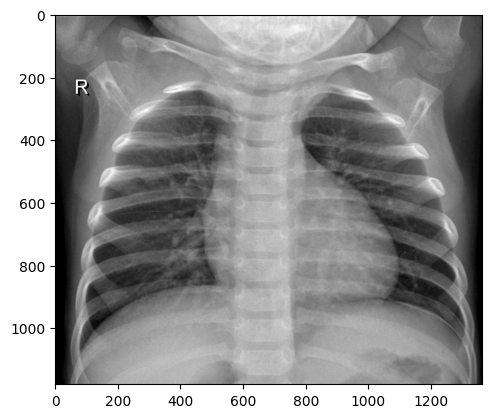

In [66]:
# converting one  images into grayscale
for i in CATEGORIES:
    path=os.path.join(DataDir,i)  # combine the main folder with category folder
    for img in os.listdir(path):
        img_array=cv2.imread(os.path.join(path,img),cv2.IMREAD_GRAYSCALE) # read the image in grey scale
        # a 2D NumPy array representing pixel intensities
        # img_array contains pixel values for only that one image.
        plt.imshow(img_array,cmap='gray')
        plt.show()
        break
    break

In [67]:
# intializing the size of the image so that every image should be in same dimension
img_size=100

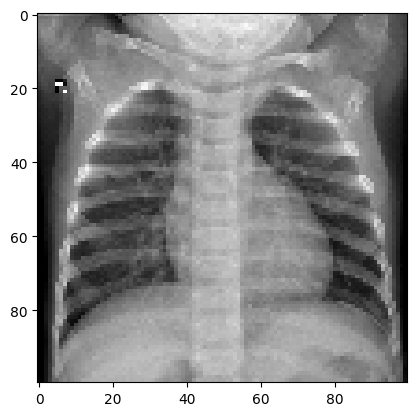

In [68]:
# image after resize and gray scale
new_array=cv2.resize(img_array,(img_size,img_size))
plt.imshow(new_array,cmap='gray')
plt.show()

array([[144, 137, 152, ...,  73,  65,  59],
       [111, 113, 113, ...,  75,  70,  65],
       [121, 125, 126, ...,  77,  68,  63],
       ...,
       [  0,   0,  19, ..., 105,  89,   8],
       [  0,   0,  19, ...,  98,  88,  12],
       [  0,   0,  20, ...,  98,  84,  15]], dtype=uint8)
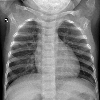

In [69]:
new_array # it shows the pixel value of the photo in the array

In [70]:
img_array

array([[171, 173, 173, ...,  60,  62,  63],
       [165, 165, 164, ...,  60,  60,  60],
       [153, 151, 152, ...,  60,  61,  61],
       ...,
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0]], dtype=uint8)

In [71]:
training_data=[]

In [72]:
img_size=100

In [73]:
# RGB has 3 channels: Red, Green, Blue → shape (height, width, 3)
# Grayscale has 1 channel: shape (height, width)
# This process is called “channel reduction”

# converting all images to grey scale
# defining the function for training data according to the categories converting the images into gray scale with resizing the image into 100 x 100
# converting it into numpy arrays
def create_training_data():
    for i in CATEGORIES:

        path=os.path.join(DataDir,i)
        class_num=CATEGORIES.index(i)

        for img in os.listdir(path):
            try:
                img_array=cv2.imread(os.path.join(path,img),cv2.IMREAD_GRAYSCALE)
                new_array=cv2.resize(img_array,(img_size,img_size))
                training_data.append([new_array,class_num])

            except Exception as e:
                pass

In [74]:
create_training_data()

In [75]:
print(len(training_data))

5226


In [76]:
training_data

[[array([[144, 137, 152, ...,  73,  65,  59],
         [111, 113, 113, ...,  75,  70,  65],
         [121, 125, 126, ...,  77,  68,  63],
         ...,
         [  0,   0,  19, ..., 105,  89,   8],
         [  0,   0,  19, ...,  98,  88,  12],
         [  0,   0,  20, ...,  98,  84,  15]], dtype=uint8),
  0],
 [array([[12, 23, 34, ..., 34, 27, 18],
         [11, 23, 32, ..., 31, 23, 12],
         [11, 23, 33, ..., 24, 18,  6],
         ...,
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0]], dtype=uint8),
  0],
 [array([[ 26,  36,  75, ...,  50,  93, 103],
         [ 28,  33,  66, ...,  42,  51, 109],
         [ 26,  30,  38, ...,  41,  40,  97],
         ...,
         [  0,   0,   0, ...,   0,   0,   0],
         [  0,   0,   0, ...,   0,   0,   0],
         [  0,   0,   0, ...,   0,   0,   0]], dtype=uint8),
  0],
 [array([[ 0,  8, 19, ..., 43, 33, 14],
         [ 0,  0, 19, ..., 41, 32, 17],
         [ 0,  0, 16, .

In [77]:
# shuffle all pneumonia and normal images should shuffle so that model can find the pattern
import random
random.shuffle(training_data)
for sample in training_data[:10]:
    print(sample)

[array([[105, 110, 125, ..., 102, 102, 105],
       [109, 117, 121, ...,  99, 104, 123],
       [116, 110, 120, ..., 100, 112, 134],
       ...,
       [ 17,  16,  17, ...,  11,  13,  14],
       [ 20,  18,  19, ...,  12,  14,  13],
       [ 18,  19,  16, ...,  12,  14,  14]], dtype=uint8), 0]
[array([[121, 158, 191, ..., 146, 147, 142],
       [116, 126, 177, ..., 147, 148, 148],
       [114, 122, 120, ..., 149, 159, 189],
       ...,
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0]], dtype=uint8), 0]
[array([[  0,  24,  69, ...,  99,  93,  78],
       [  0,   2,  58, ...,  98,  96,  78],
       [  0,   0,  33, ..., 102,  93,  79],
       ...,
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0]], dtype=uint8), 1]
[array([[  3,   3,   3, ..., 145, 124, 121],
       [  1,   1,   3, ..., 132, 113, 106],
       [  1,   0,   2, ...

In [78]:
X=[]
y=[]

In [79]:
# spliting the features(independent variable) and labels(dependent variable)
for features,label in training_data:
    X.append(features)
    y.append(label)

In [80]:
# images when we are feeding to our CNN models it is always expected to have 4D
X = np.array(X).reshape(-1, img_size, img_size, 1)
y = np.array(y)
print(X[0].reshape(-1,img_size,img_size,1))

[[[[105]
   [110]
   [125]
   ...
   [102]
   [102]
   [105]]

  [[109]
   [117]
   [121]
   ...
   [ 99]
   [104]
   [123]]

  [[116]
   [110]
   [120]
   ...
   [100]
   [112]
   [134]]

  ...

  [[ 17]
   [ 16]
   [ 17]
   ...
   [ 11]
   [ 13]
   [ 14]]

  [[ 20]
   [ 18]
   [ 19]
   ...
   [ 12]
   [ 14]
   [ 13]]

  [[ 18]
   [ 19]
   [ 16]
   ...
   [ 12]
   [ 14]
   [ 14]]]]


In [81]:
!ls /content/chest_xray

custom_pre_trained_model_10.h5	model_10.h5  model_vit_10.h5  test  train  val


In [82]:
!ls /content/chest_xray/train

NORMAL	PNEUMONIA


In [83]:
!ls /content/chest_xray/train/PNEUMONIA

 person1000_bacteria_2931.jpeg	 person30_bacteria_154.jpeg
 person1000_virus_1681.jpeg	 person30_bacteria_155.jpeg
 person1001_bacteria_2932.jpeg	 person30_bacteria_156.jpeg
 person1002_bacteria_2933.jpeg	 person30_bacteria_157.jpeg
 person1003_bacteria_2934.jpeg	 person30_bacteria_158.jpeg
 person1003_virus_1685.jpeg	 person310_bacteria_1450.jpeg
 person1004_bacteria_2935.jpeg	 person310_bacteria_1451.jpeg
 person1004_virus_1686.jpeg	 person310_virus_633.jpeg
 person1005_bacteria_2936.jpeg	 person311_bacteria_1452.jpeg
 person1005_virus_1688.jpeg	 person311_bacteria_1453.jpeg
 person1006_bacteria_2937.jpeg	 person311_virus_634.jpeg
 person1007_bacteria_2938.jpeg	 person312_bacteria_1454.jpeg
 person1007_virus_1690.jpeg	 person312_bacteria_1455.jpeg
 person1008_bacteria_2939.jpeg	 person312_bacteria_1456.jpeg
 person1008_virus_1691.jpeg	 person312_virus_635.jpeg
 person1009_virus_1694.jpeg	 person313_bacteria_1457.jpeg
 person100_virus_184.jpeg	 person313_bacteria_1458.jpeg
 person1010

In [84]:
# setting validation data
validation_data=[]
DataDir_val = "/content/chest_xray/val"


In [85]:
# we do it for the same
def create_validating_data():
    for i in CATEGORIES:

        path=os.path.join(DataDir_val,i)
        class_num=CATEGORIES.index(i)

        for img in os.listdir(path):
            try:
                img_array=cv2.imread(os.path.join(path,img),cv2.IMREAD_GRAYSCALE)
                new_array=cv2.resize(img_array,(img_size,img_size))
                validation_data.append([new_array,class_num])

            except Exception as e:
                pass

In [86]:
create_validating_data()
print(len(validation_data))

16


In [87]:
import random
random.shuffle(validation_data)
for sample in validation_data[:10]:
    print(sample)

[array([[ 0,  5, 16, ..., 79, 47, 29],
       [ 0,  3, 15, ..., 78, 47, 27],
       [ 0,  3, 16, ..., 77, 52, 25],
       ...,
       [ 1,  1,  0, ...,  2,  2,  2],
       [ 1,  1,  0, ...,  1,  2,  2],
       [ 1,  1,  1, ...,  2,  2,  2]], dtype=uint8), 1]
[array([[ 13,  24,  31, ...,   0,   0,   0],
       [ 12,  24,  96, ...,   0,   0,   0],
       [ 11, 254, 163, ...,   0,   0,   0],
       ...,
       [  0,  19,  28, ...,   0,   0,   0],
       [  0,  20,  27, ...,   0,   0,   0],
       [  0,  18,  28, ...,   0,   0,   0]], dtype=uint8), 1]
[array([[64, 63, 64, ..., 97, 93, 93],
       [51, 52, 50, ..., 90, 92, 90],
       [39, 41, 44, ..., 96, 86, 86],
       ...,
       [16, 51, 78, ...,  2,  2,  6],
       [28, 56, 80, ...,  2,  1,  8],
       [35, 61, 87, ...,  2, 10,  7]], dtype=uint8), 1]
[array([[  0,   0,   0, ...,   6,   6,   6],
       [  0,   0,   0, ...,   6,   6,   6],
       [  0,   0,   0, ...,   6,   6,   6],
       ...,
       [  3,   3,   3, ..., 222,  51,   7]

In [88]:
X_val=[]
y_val=[]

In [89]:
for features,label in validation_data:
    X_val.append(features)
    y_val.append(label)

In [90]:
X_val = np.array(X_val).reshape(-1, img_size, img_size, 1)
y_val = np.array(y_val)

In [91]:
# model building

In [92]:
# feture scaling
# Pixels value ranges from 0 to 255, 0 means black, 255 means white....
# In order to scale it down to a scale of 0 to 1, we are performing this step
X = X/255.0
x_val = X_val/255.0

In [93]:
X.shape

(5226, 100, 100, 1)

In [94]:
X_val.shape

(16, 100, 100, 1)

In [95]:
# intializing the neural network layer for training the model
model= Sequential()
# 64-> number of filter in filter detector
# (3,3)-> matrix size for filter detector
# usually dont use dropout.create a model check how the model behave and then add the dropout,when see overfitting situation
model.add(Conv2D(64,(3,3),input_shape=X.shape[1:]))
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(.2))

model.add(Conv2D(128,(3,3)))
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(.2))

model.add(Conv2D(256,(3,3)))
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(.2))

model.add(Flatten())
model.add(Dense(64))

model.add(Dropout(.5))
model.add(Dense(1))  # means its a binary classifcation problem
model.add(Activation('sigmoid'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [96]:
# summary of the model
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 98, 98, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 49, 49, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 47, 47, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 23, 23, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 21, 21, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 21, 21, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,638,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,008,193 (7.66 MB)

 Trainable params: 2,008,193 (7.66 MB)

 Non-trainable params: 0 (0.00 B)

In [97]:
# compilation
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [98]:
# fittting the model with 10 epochs and using the validation data we have created
model.fit(X,y,batch_size=4,epochs=10,validation_data=(x_val, y_val))

Epoch 1/10
1307/1307 ━━━━━━━━━━━━━━━━━━━━ 263s 199ms/step - accuracy: 0.8148 - loss: 0.4209 - val_accuracy: 0.8750 - val_loss: 0.2326
Epoch 2/10
1307/1307 ━━━━━━━━━━━━━━━━━━━━ 248s 190ms/step - accuracy: 0.9440 - loss: 0.1664 - val_accuracy: 0.8750 - val_loss: 0.3490
Epoch 3/10
1307/1307 ━━━━━━━━━━━━━━━━━━━━ 271s 197ms/step - accuracy: 0.9511 - loss: 0.1344 - val_accuracy: 0.9375 - val_loss: 0.1567
Epoch 4/10
1307/1307 ━━━━━━━━━━━━━━━━━━━━ 256s 192ms/step - accuracy: 0.9639 - loss: 0.1049 - val_accuracy: 0.8750 - val_loss: 0.1990
Epoch 5/10
1307/1307 ━━━━━━━━━━━━━━━━━━━━ 264s 194ms/step - accuracy: 0.9606 - loss: 0.1117 - val_accuracy: 0.8125 - val_loss: 0.3377
Epoch 6/10
1307/1307 ━━━━━━━━━━━━━━━━━━━━ 261s 200ms/step - accuracy: 0.9658 - loss: 0.0884 - val_accuracy: 1.0000 - val_loss: 0.0306
Epoch 7/10
1307/1307 ━━━━━━━━━━━━━━━━━━━━ 258s 197ms/step - accuracy: 0.9715 - loss: 0.0723 - val_accuracy: 1.0000 - val_loss: 0.0931
Epoch 8/10
1307/1307 ━━━━━━━━━━━━━━━━━━━━ 257s 197ms/step - ac

In [99]:
model.save("/content/drive/MyDrive/chest_xray/model_1_tapas.h5")



In [100]:
# importing the library for testing


In [101]:
import cv2
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from tensorflow.keras.models import load_model

In [102]:
CATEGORIES = ["NORMAL", "PNEUMONIA"]

In [103]:
# function for preparing the image for predicting the class
def prepare(image):
    img_size=100
    #img_array=cv2.imread(image,cv2.IMREAD_GRAYSCALE)
    img=tf.keras.preprocessing.image.load_img(image, color_mode='grayscale', target_size=(img_size,img_size))
    new_array=tf.keras.preprocessing.image.img_to_array(img)

    return new_array.reshape(-1,img_size,img_size,1)

In [104]:
!ls "/content/drive/MyDrive/chest_xray"


model_1_tapas.h5


In [106]:
!ls "/content/chest_xray/test"

NORMAL	PNEUMONIA


In [107]:
model = tf.keras.models.load_model("/content/drive/MyDrive/chest_xray/model_1_tapas.h5")

In [108]:
!ls "/content/chest_xray/test/PNEUMONIA"

person100_bacteria_475.jpeg  person1633_virus_2829.jpeg
person100_bacteria_477.jpeg  person1634_virus_2830.jpeg
person100_bacteria_478.jpeg  person1635_virus_2831.jpeg
person100_bacteria_479.jpeg  person1637_virus_2834.jpeg
person100_bacteria_480.jpeg  person1640_virus_2839.jpeg
person100_bacteria_481.jpeg  person1641_virus_2840.jpeg
person100_bacteria_482.jpeg  person1642_virus_2842.jpeg
person101_bacteria_483.jpeg  person1643_virus_2843.jpeg
person101_bacteria_484.jpeg  person1644_virus_2844.jpeg
person101_bacteria_485.jpeg  person1645_virus_2845.jpeg
person101_bacteria_486.jpeg  person1647_virus_2848.jpeg
person102_bacteria_487.jpeg  person1649_virus_2850.jpeg
person103_bacteria_488.jpeg  person1650_virus_2852.jpeg
person103_bacteria_489.jpeg  person1650_virus_2854.jpeg
person103_bacteria_490.jpeg  person1651_virus_2855.jpeg
person104_bacteria_491.jpeg  person1653_virus_2858.jpeg
person104_bacteria_492.jpeg  person1653_virus_2859.jpeg
person108_bacteria_504.jpeg  person1655_virus_28

In [109]:
image="/content/chest_xray/test/PNEUMONIA/person146_bacteria_700.jpeg"

In [110]:
prediction=model.predict([prepare(image)/255.0])
print(prediction)
print(round(prediction[0][0]))
print(CATEGORIES[int(round(prediction[0][0]))])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
[[0.9985092]]
1
PNEUMONIA


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=('Tensor(shape=(1, 100, 100, 1))',)
  warnings.warn(msg)


In [111]:
# caluclating test accuracy

# importing necessary libraries
import os
import cv2
import numpy as np
import tensorflow as tf
from keras.models import load_model

# set the path for test data
test_dir = "/content/chest_xray/test"

# define categories
CATEGORIES = ["NORMAL", "PNEUMONIA"]

# set image size
img_size = 100

# load the saved model
model = load_model('/content/drive/MyDrive/chest_xray/model_1_tapas.h5')

# initialize lists for storing test data
X_test = []
y_test = []

# loop through the test data directory and extract the images and their labels
for category in CATEGORIES:
    path = os.path.join(test_dir, category)
    class_num = CATEGORIES.index(category)
    for img in os.listdir(path):
        try:
            img_array = cv2.imread(os.path.join(path, img), cv2.IMREAD_GRAYSCALE)
            new_array = cv2.resize(img_array, (img_size, img_size))
            X_test.append(new_array)
            y_test.append(class_num)
        except Exception as e:
            pass

# convert test data to numpy arrays
X_test = np.array(X_test).reshape(-1, img_size, img_size, 1)
y_test = np.array(y_test)

# normalize test data
X_test = X_test / 255.0

# calculate test accuracy
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=2)

# print test accuracy
print('Test accuracy:', test_acc)


20/20 - 9s - 465ms/step - accuracy: 0.7468 - loss: 1.2605
Test accuracy: 0.7467948794364929


# Pre-Trained Model

In [112]:
# import necessary libraries
import tensorflow as tf
from tensorflow.keras.applications.vgg16 import VGG16
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.models import Model # allows us to combine pre-trained base + new layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator # helps load and preprocess images on the fly.

# define image size
img_size = 100

# load the pre-trained model (VGG16)
base_model = VGG16(input_shape=(img_size,img_size,3), include_top=False, weights='imagenet')

# freeze the layers of the pre-trained model
for layer in base_model.layers:  # dont want to train it again .want to use default model without further training
    layer.trainable = False

# add custom layers for classification
x = Flatten()(base_model.output)
x = Dense(256, activation='relu')(x)
x = Dense(128, activation='relu')(x)
x = Dense(64, activation='relu')(x)
predictions = Dense(1, activation='sigmoid')(x)

# create a new model
model = Model(inputs=base_model.input, outputs=predictions) # Creates a new model: VGG16 base + custom layers.

# compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# define the image generators for training and validation data
train_datagen = ImageDataGenerator(rescale=1./255, shear_range=0.2, zoom_range=0.2, horizontal_flip=True)
val_datagen = ImageDataGenerator(rescale=1./255)

# specify the training and validation data directories
train_dir = '/content/chest_xray/train'
val_dir = '/content/chest_xray/val'

# create the image generators for training and validation data
train_generator = train_datagen.flow_from_directory(train_dir, target_size=(img_size, img_size), batch_size=32, class_mode='binary')
val_generator = val_datagen.flow_from_directory(val_dir, target_size=(img_size, img_size), batch_size=32, class_mode='binary')

# train the model
model.fit(train_generator, epochs=10, validation_data=val_generator)

# evaluate the model on test data
test_dir = '/content/chest_xray/test'
test_datagen = ImageDataGenerator(rescale=1./255)
test_generator = test_datagen.flow_from_directory(test_dir, target_size=(img_size, img_size), batch_size=32, class_mode='binary', shuffle=False)
test_loss, test_acc = model.evaluate(test_generator)
print('Test accuracy:', test_acc)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Found 5226 images belonging to 2 classes.
Found 16 images belonging to 2 classes.


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 605s 4s/step - accuracy: 0.8586 - loss: 0.3025 - val_accuracy: 0.8125 - val_loss: 0.6310
Epoch 2/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 595s 4s/step - accuracy: 0.9471 - loss: 0.1461 - val_accuracy: 0.8750 - val_loss: 0.2703
Epoch 3/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 587s 4s/step - accuracy: 0.9481 - loss: 0.1415 - val_accuracy: 0.7500 - val_loss: 0.4233
Epoch 4/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 588s 4s/step - accuracy: 0.9505 - loss: 0.1289 - val_accuracy: 0.9375 - val_loss: 0.2540
Epoch 5/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 621s 4s/step - accuracy: 0.9481 - loss: 0.1353 - val_accuracy: 0.7500 - val_loss: 0.5283
Epoch 6/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 589s 4s/step - accuracy: 0.9620 - loss: 0.1030 - val_accuracy: 0.7500 - val_loss: 0.5185
Epoch 7/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 587s 4s/step - accuracy: 0.9660 - loss: 0.1035 - val_accuracy: 0.9375 - val_loss: 0.1994
Epoch 8/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 589s 4s/step - accuracy: 0.9552 - loss: 0.1218 - val_accu

In [113]:
# Save the trained model as HDF5
model.save("/content/drive/MyDrive/chest_xray/model_vgg_tapas.h5")


In [114]:
model = tf.keras.models.load_model("/content/drive/MyDrive/chest_xray/model_vgg_tapas.h5")

In [115]:
model.summary()

Model: "functional_85"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 100, 100, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 100, 100, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 50, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 50, 50, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 50, 50, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 25, 25, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 25, 25, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 25, 25, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 25, 25, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 12, 12, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 6, 6, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,935,811 (60.79 MB)

 Trainable params: 1,221,121 (4.66 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

 Optimizer params: 2 (12.00 B)

In [116]:
# evaluate the model on test data
test_dir = '/content/chest_xray/test'
test_datagen = ImageDataGenerator(rescale=1./255)
test_generator = test_datagen.flow_from_directory(test_dir, target_size=(img_size, img_size), batch_size=32, class_mode='binary', shuffle=False)
test_loss, test_acc = model.evaluate(test_generator)
print('Test accuracy:', test_acc)

Found 624 images belonging to 2 classes.
20/20 ━━━━━━━━━━━━━━━━━━━━ 75s 4s/step - accuracy: 0.8387 - loss: 0.5409
Test accuracy: 0.8926281929016113
